In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import ScalarFormatter

In [2]:
import os
net_name = "core"  # change to "core_<variant>" for a model variant
CSV_PATH = f"{net_name}/metrics/lgn_unit_power/lgn_unit_power_spectrum.csv"

lgn_power = pd.read_csv(CSV_PATH)
print(lgn_power.shape)
lgn_power.head(3)

(139200, 10)


,angle,node_id,f,n_trials,mean_power,std_power,sem_power,mean_power_norm,std_power_norm,sem_power_norm
0,0,0,"[0.0, 0.9992000000000006, 1.9984000000000013, ...",10,"[4.869069418677183, 22.295819611443306, 45.305...","[7.1392430442663875, 18.670422568083556, 31.28...","[2.257626878939609, 5.9041060192954165, 9.8932...","[0.0008093587527884692, 0.003774760907354424, ...","[0.000989332031078661, 0.002143513331680994, 0...","[0.0003128542580369058, 0.00067783843230479, 0..."
1,0,1,"[0.0, 0.9992000000000006, 1.9984000000000013, ...",10,"[5.0841603960148385, 16.704196642126966, 26.67...","[6.242326049896585, 17.970285813699466, 17.972...","[1.9739968215075094, 5.682703337550256, 5.6833...","[0.0011756113758424756, 0.00356533120683264, 0...","[0.0009932515332947895, 0.0024135714125093693,...","[0.0003140937134666102, 0.0007632382958999418,..."
2,0,2,"[0.0, 0.9992000000000006, 1.9984000000000013, ...",10,"[6.134203510094199, 22.670170912085744, 41.437...","[4.702689730708604, 12.470173058255916, 19.190...","[1.487121067812307, 3.943414968055628, 6.06846...","[0.001164143895642238, 0.004288429471193325, 0...","[0.0007743039045218355, 0.0017929616465449773,...","[0.000244856393945055, 0.0005669842560407896, ..."


In [3]:
def str2arr(s):
    """Parse a string-encoded list (as saved by arr_to_str) to a numpy array."""
    s = s.strip()
    if s.startswith("["):
        s = s[1:-1]
    return np.array([float(x) for x in s.split(",")])

# Parse all array-valued columns produced by analysis_lgn_unit_power_spectrum.py.
# sem_power is the standard deviation of the mean (std / sqrt(n_trials)),
# computed in the analysis script as in fig1C_dg_power.ipynb.
array_cols = [
    "f",
    "mean_power", "std_power", "sem_power",
    "mean_power_norm", "std_power_norm", "sem_power_norm",
]
for col in array_cols:
    if col in lgn_power.columns:
        lgn_power[col] = lgn_power[col].apply(str2arr)

In [4]:
# Average mean_power across all angles for each unit
# Result: one power spectrum per unit, averaged over angles
unit_power = (
    lgn_power.groupby("node_id")["mean_power"]
    .apply(lambda rows: np.mean(np.vstack(rows.values), axis=0))
    .reset_index()
)
unit_power.columns = ["node_id", "power_avg_angles"]

# Reference frequency axis (same for all rows)
f = lgn_power["f"].iloc[0]

print(f"Units: {len(unit_power)}  |  Freq bins: {len(f)}  |  f range: {f[0]:.1f}–{f[-1]:.1f} Hz")

Units: 17400  |  Freq bins: 251  |  f range: 0.0–249.8 Hz


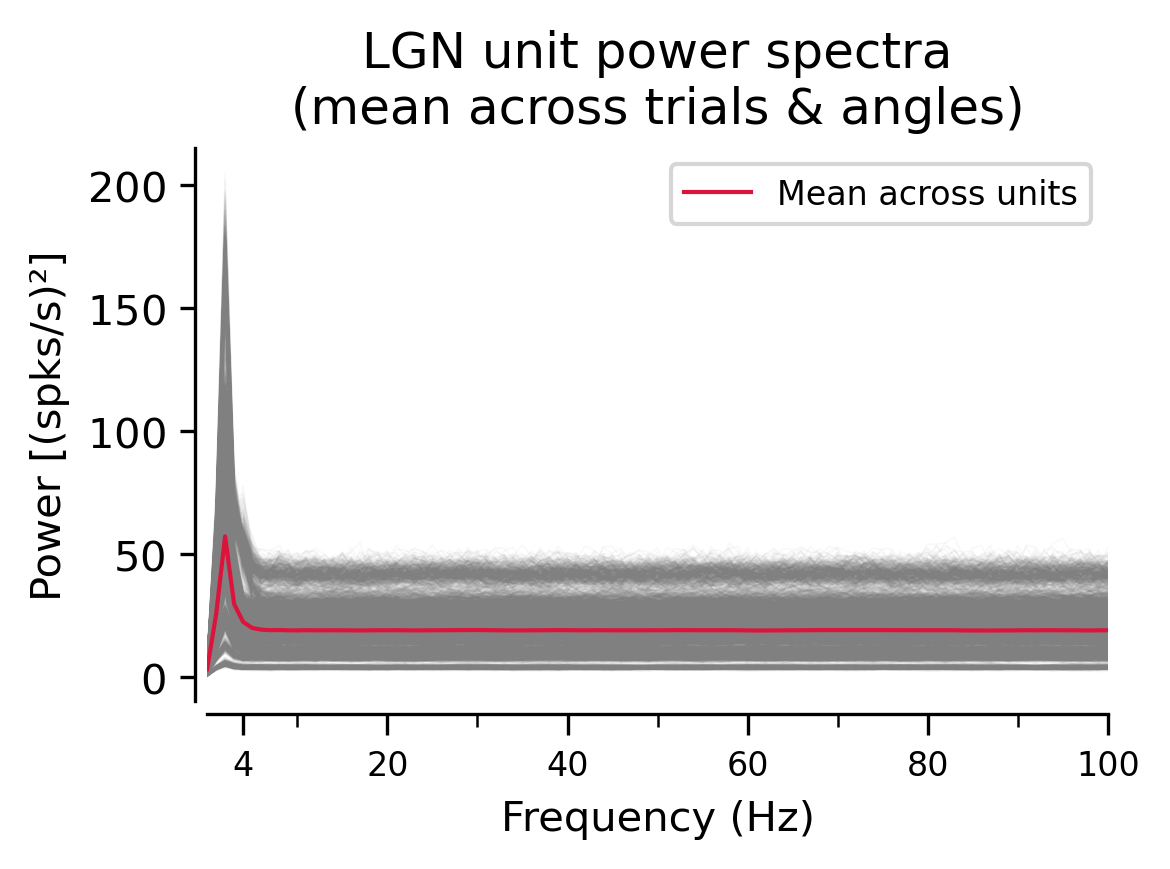

In [5]:
# Stack all unit spectra into a matrix: (n_units × n_freq)
power_matrix = np.vstack(unit_power["power_avg_angles"].values)

# Grand mean and sem across units
grand_mean = power_matrix.mean(axis=0)
grand_sem  = power_matrix.std(axis=0) / np.sqrt(power_matrix.shape[0])

fig, ax = plt.subplots(figsize=(4, 3), dpi=300)

# Individual unit traces in grey (subsample if >5000 units for speed)
n_units = power_matrix.shape[0]
step = max(1, n_units // 5000)
for row in power_matrix[::step]:
    ax.plot(f, row, color="grey", alpha=0.05, linewidth=0.4, rasterized=True)

# Grand mean ± sem
# ax.fill_between(
#     f,
#     grand_mean - 1.96 * grand_sem,
#     grand_mean + 1.96 * grand_sem,
#     color="#1f77b4",
#     alpha=0.5,
#     linewidth=0,
#     label="Mean ± 95% CI across units",
# )
ax.plot(f, grand_mean, color="crimson", linewidth=1, label="Mean across units")

sns.despine()
ax.spines["left"].set_position(("outward", 3))
ax.spines["bottom"].set_position(("outward", 3))

ax.set_xlim([0, 100])
ax.set_xticks([4, 20, 40, 60, 80, 100])
ax.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
ax.set_xticks([10, 30, 50, 70, 90], minor=True)
ax.tick_params(axis='x', which='major', length=5)
ax.tick_params(axis='x', which='minor', length=3)

formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((-4, 4))
ax.yaxis.set_major_formatter(formatter)
ax.ticklabel_format(axis="y", style="scientific", scilimits=(-4, 4))

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power [(spks/s)²]")
ax.set_title("LGN unit power spectra\n(mean across trials & angles)")
ax.legend(loc="upper right", fontsize=8)

fig.tight_layout()
fig.savefig(
    "paper_figs/dg_lgn_units_power.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

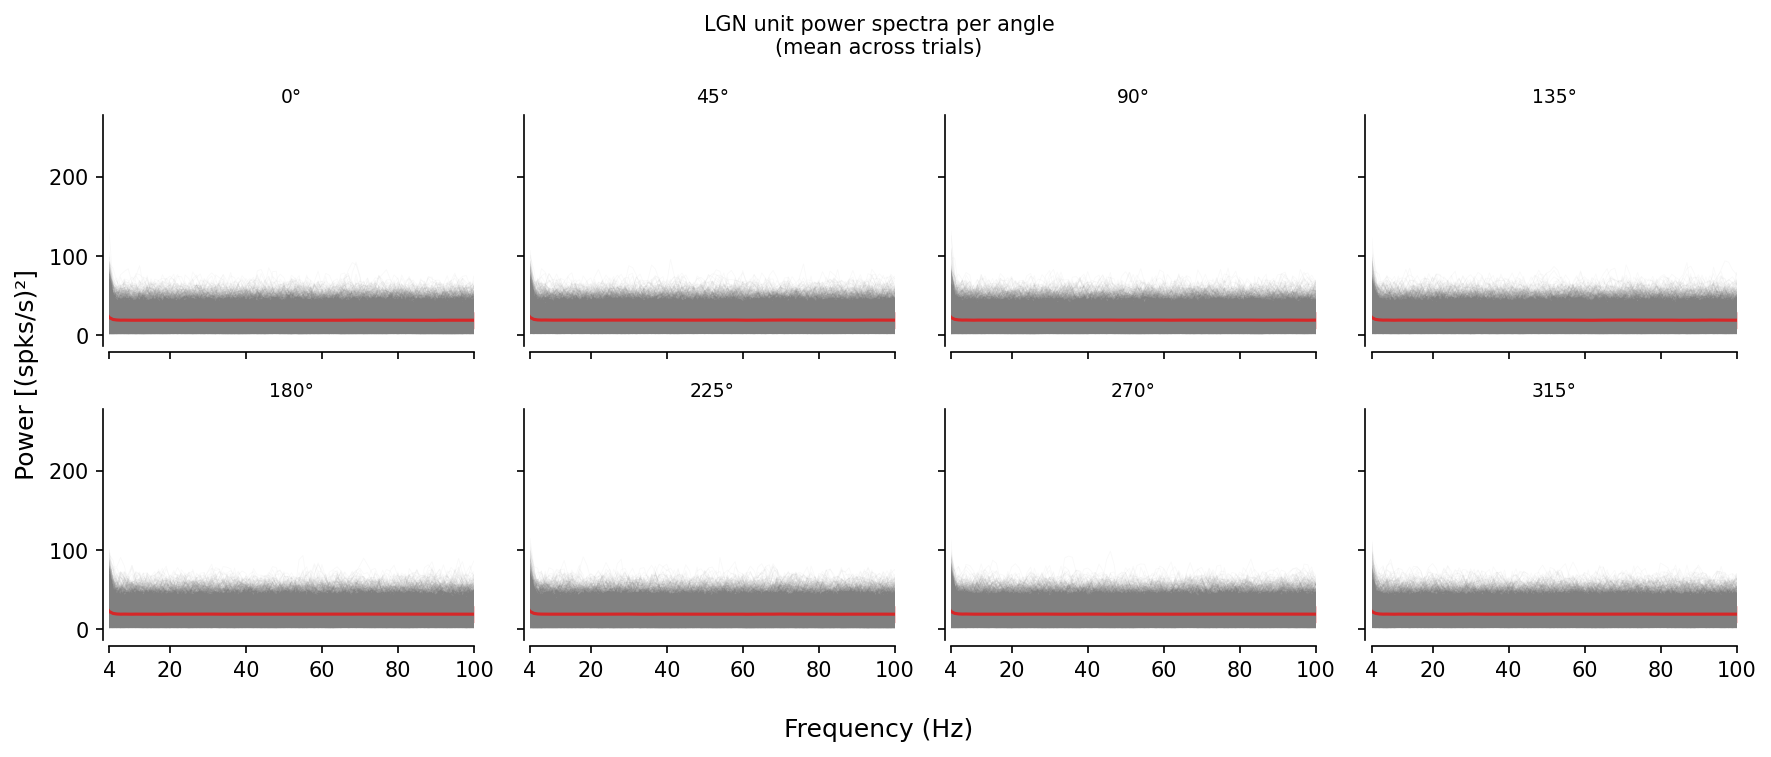

In [6]:
# Same plot with per-angle panels
ANGLES = [0, 45, 90, 135, 180, 225, 270, 315]

fig, axes = plt.subplots(2, 4, figsize=(12, 5), dpi=150, sharex=True, sharey=True)
axes = axes.flatten()

for ax, angle in zip(axes, ANGLES):
    subset = lgn_power[lgn_power["angle"] == angle]
    pm = np.vstack(subset["mean_power"].values)
    gm = pm.mean(axis=0)
    gs = pm.std(axis=0)

    step = max(1, len(pm) // 5000)
    for row in pm[::step]:
        ax.plot(f, row, color="grey", alpha=0.05, linewidth=0.4, rasterized=True)

    ax.fill_between(f, gm - gs, gm + gs, color="#d62728", alpha=0.25, linewidth=0)
    ax.plot(f, gm, color="#d62728", linewidth=1.5)

    sns.despine(ax=ax)
    ax.spines["left"].set_position(("outward", 3))
    ax.spines["bottom"].set_position(("outward", 3))

    ax.set_xlim([4, 100])
    ax.set_xticks([4, 20, 40, 60, 80, 100])
    ax.set_xticklabels([4, 20, 40, 60, 80, 100])

    formatter = ScalarFormatter(useMathText=True)
    formatter.set_powerlimits((-4, 4))
    ax.yaxis.set_major_formatter(formatter)
    ax.ticklabel_format(axis="y", style="scientific", scilimits=(-4, 4))

    ax.set_title(f"{angle}°", fontsize=9)

fig.supxlabel("Frequency (Hz)")
fig.supylabel("Power [(spks/s)²]")
fig.suptitle("LGN unit power spectra per angle\n(mean across trials)", fontsize=10)
fig.tight_layout()
plt.show()